In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch import Tensor
from torchvision import transforms
import h5py

import matplotlib.pyplot as plt
import matplotlib.animation as animation

from IPython.display import HTML

import gc
import math
import random

# for deleting old best models
import os
import glob


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device is {device}")

Device is cpu


In [2]:
warm_start = False

data_resolution = "224x224"
# from data resolution
num_input_params = 224 * 224
data_location = "../datasets/DDD-20-single-recording/out_files/recording_bin50msAPS.hdf5"

# for models
save_path = "./models/"
# set hyperparameters
num_epochs = 50
# Chosen to divide 6000 well, since that's the sequence of training consequential training indices the original utility gives, not the biggest deal
clean_old_models = True
batch_size = 60
learning_rate = 1e-3
weight_decay = 1e-4
use_aps = True
use_stated = True
normalisation_precision = np.float16
# "new" or None
preprocessing_method = None
# ---------------------------- These all relate to preprocessing_method "new" ----------------------------
# if the average steering angle of the absolute values of the batch is below this threshold, the batch is pruned
# picked it more gentle than the 5, since it's an average. The original method removed about two thirds of the data.
pruning_threshold = 2.0
# less than 15 km/h is considered not fast enough
speed_threshold = 15.0

In [3]:
# ~40 seconds
with h5py.File(data_location, "r") as f:
    # headers = pd.DataFrame(np.array(h5py.File(data_location)))
    # print(f"The headers accessible are as such:\n{headers}")
    dvs_frame = np.array(f[f"dvs_frame_{data_resolution}"])
    speeds = np.array(f["vehicle_speed"])
    train_idxs = np.array(f["train_idxs"])
    test_idxs = np.array(f["test_idxs"])
    steering_angles = np.array(f["steering_wheel_angle"])
    if use_aps:
        aps_frame = np.array(f["aps_frame"])

In [4]:
# TODO: Make this into a function, or a lambda to transform!
# Normalise DVS/APS Frames
# As the max/min of the train/test will always be fixed to 0 and 255 respectively by the limits of the sensor, we don't need to worry about
# contaminating the test set with the train set's max/min
# We could find these values dynamically by np.max/min, but we know the max/min of the DVS/APS frames will always be 0 and 255 respectively
dvs_min, dvs_max = 0, 255.0
aps_min, aps_max = 0, 255.0
inv_dvs_max = 1 / dvs_max
inv_aps_max = 1 / aps_max


print(f"DVS frames had a min of {dvs_min}, max of {dvs_max} and an average of {np.average(dvs_frame)}.")
# normalise in batches to stop kernel crashing due to memory
normalisation_batch_size = 1000
new_dvs_frame = np.empty_like(dvs_frame, dtype=normalisation_precision)
for i in range(0, len(dvs_frame), normalisation_batch_size):
    new_dvs_frame[i:i+normalisation_batch_size] = dvs_frame[i:i+normalisation_batch_size] * inv_dvs_max # this is shorthand for (batch - dvs_min) / (dvs_max - dvs_min) as dvs_min is 0

dvs_frame = new_dvs_frame
print(f"After normalisation, DVS has a min of {dvs_frame.min()}, max of {dvs_frame.max()} and an average of {np.average(dvs_frame)}.")

if use_aps:
    print(f"APS frames had a min of {aps_min}, max of {aps_max} and an average of {np.average(aps_frame)}.")
    # transform aps frame to correct 224 x 224 size
    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((224, 224)),
        ])
    
    new_aps_frame = np.empty((aps_frame.shape[0], 224, 224), dtype=normalisation_precision)
    for i in range(0, len(aps_frame), normalisation_batch_size):
        for j in range(min(normalisation_batch_size, len(aps_frame) - i)):
            new_aps_frame[i + j] = transform(aps_frame[i + j])
        new_aps_frame[i:i+normalisation_batch_size] = new_aps_frame[i:i+normalisation_batch_size] * inv_aps_max # this is shorthand for (batch - aps_min) / (aps_max - aps_min) as aps_min is 0
    
    aps_frame = new_aps_frame
    print(f"After normalisation, APS has a min of {aps_frame.min()}, max of {aps_frame.max()} and an average of {np.average(aps_frame)}.")


DVS frames had a min of 0, max of 255.0 and an average of 81.51208719088106.


/home/oltans/virtual_environments/snn/lib/python3.12/site-packages/numpy/lib/function_base.py:522: RuntimeWarning: overflow encountered in cast
  scl = avg_as_array.dtype.type(a.size/avg_as_array.size)


After normalisation, DVS has a min of 0.0, max of 1.0 and an average of 0.319580078125.
APS frames had a min of 0, max of 255.0 and an average of 125.41317191131171.
After normalisation, APS has a min of 0.0, max of 1.0 and an average of 0.49169921875.


In [5]:
if use_aps:
    # 3 to have it be B x H x W x C
    combined_frames = np.stack((dvs_frame, aps_frame), axis=3)
    print(f"Combined frames shape is {combined_frames.shape}.")
    del dvs_frame, aps_frame
    gc.collect()
else:
    combined_frames = np.expand_dims(dvs_frame, axis=3)
    print(f"Combined frames shape is {combined_frames.shape}.")
    del dvs_frame
    gc.collect()

Combined frames shape is (40960, 224, 224, 2).


In [6]:
train_frames = combined_frames[train_idxs]
test_frames = combined_frames[test_idxs]
train_angles = steering_angles[train_idxs]
test_angles = steering_angles[test_idxs]
train_speeds = speeds[train_idxs]

del steering_angles, combined_frames, speeds, train_idxs, test_idxs
gc.collect()

0

In [7]:
# TODO figure out how to work this in combination to lazy loading
if preprocessing_method:
    if preprocessing_method == "new":
        '''
        The goal is to remove the sections where the steering angle is low, without removing the sequentiality of the data.
        Load the data in, batch_size at a time, and check if the average steering angle is below a certain threshold.
        If it is, remove the batch 70% of the time.
        '''
        
        discarded_batches = []
        for i in range(0, len(train_frames), batch_size):
            batch = train_frames[i:i+batch_size]
            if (np.average(np.absolute(train_angles[i:i+batch_size])) < pruning_threshold and random.random() < 0.7):
                discarded_batches.append(i)

            elif np.average(train_speeds[i:i+batch_size]) < speed_threshold:
                discarded_batches.append(i)

        indices_to_remove = []
        for batch_start in discarded_batches:
            indices_to_remove.extend(range(batch_start, min((batch_start + batch_size), len(train_frames))))

        train_frames = np.delete(train_frames, indices_to_remove, axis=0)
        train_angles = np.delete(train_angles, indices_to_remove, axis=0)
        train_speeds = np.delete(train_speeds, indices_to_remove, axis=0)
        
        print(f"Discarded {len(discarded_batches)} batches, as their average was below the thresholds, totalling {len(indices_to_remove)} frames.")
        print(f"{len(train_frames)} frames, with average steering angle of {np.average(train_angles)} and average speed of {np.average(train_speeds)} remain.") 
        del indices_to_remove, train_speeds
        gc.collect()
    else:
        raise ValueError("Preprocessing method not recognised.")
        

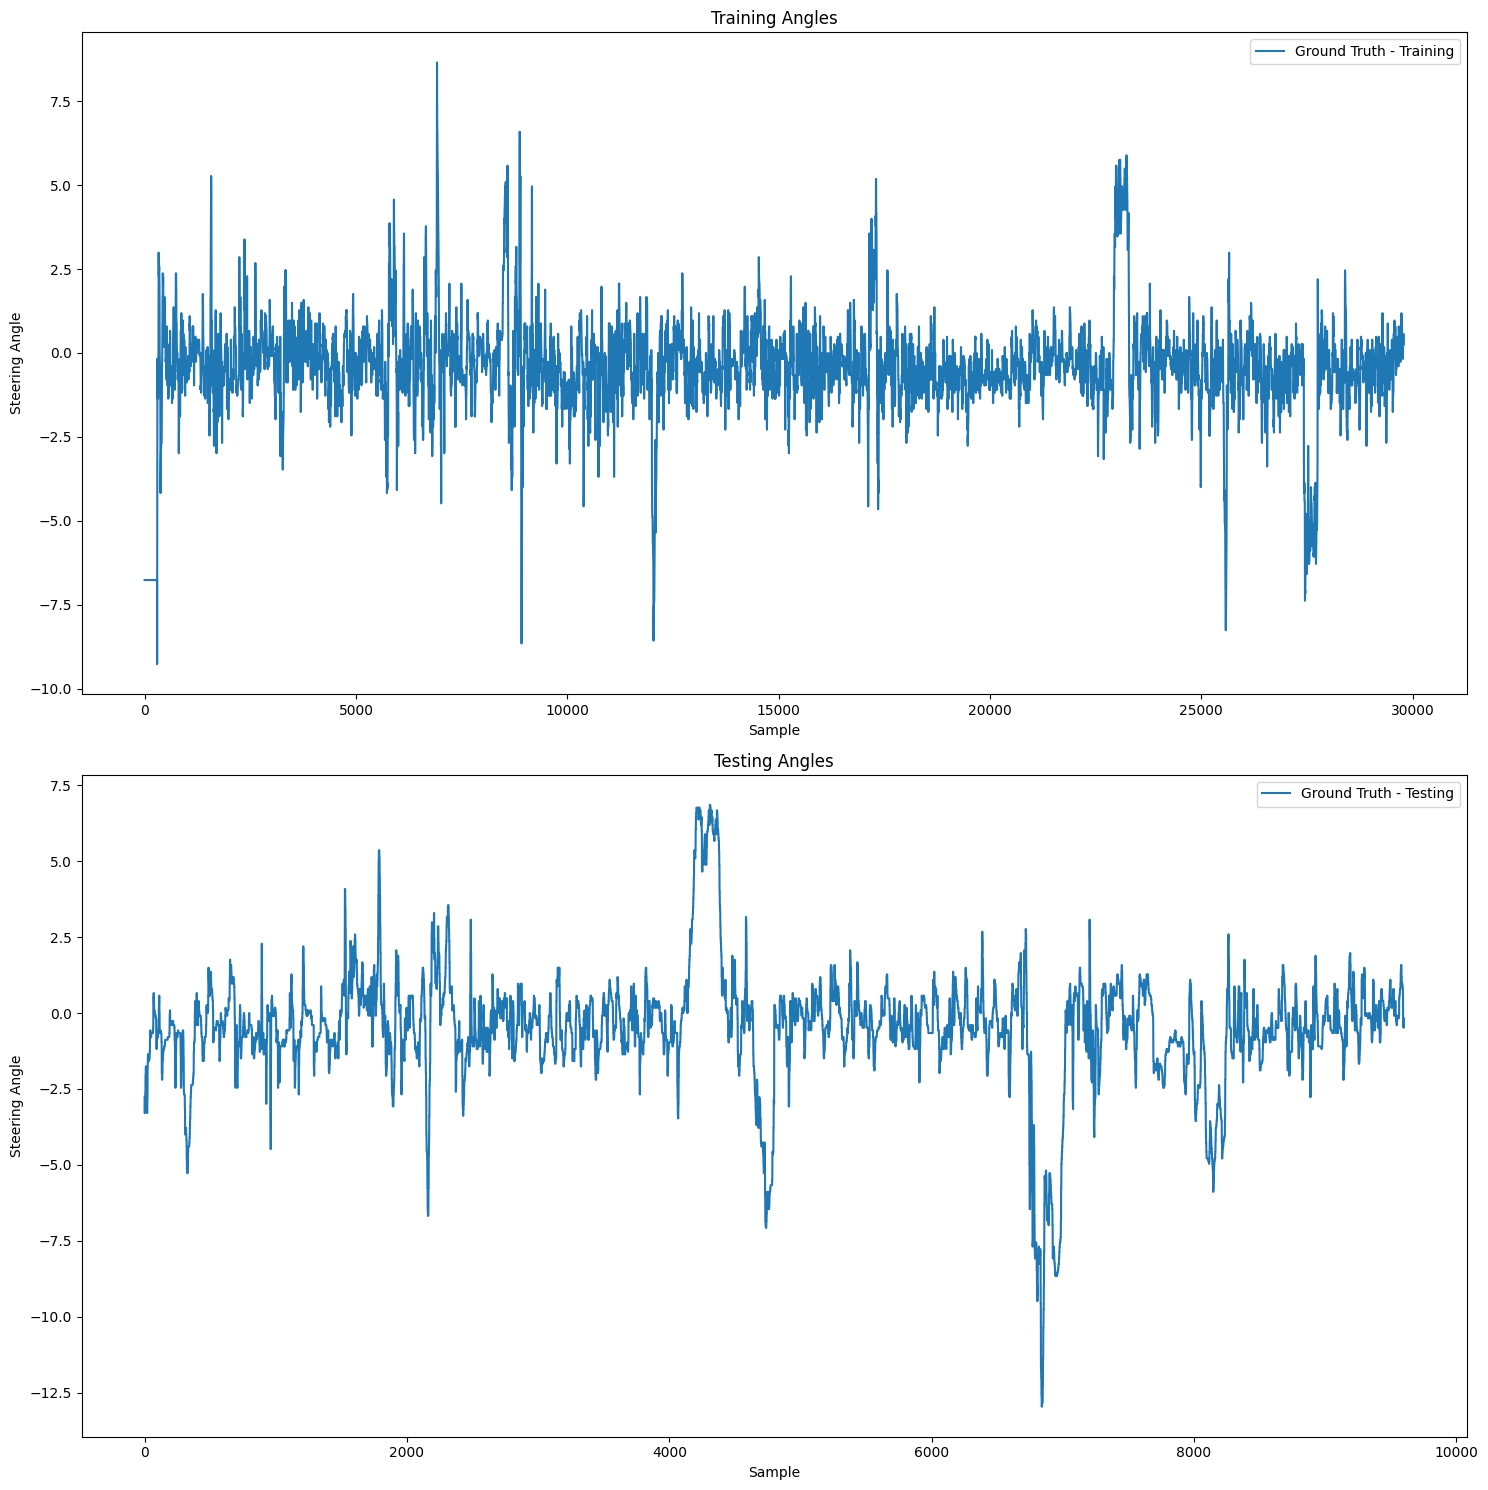

In [8]:
#Rename to fit convention
train_X, train_y = train_frames, train_angles
test_X, test_y = test_frames, test_angles

del train_frames, train_angles, test_frames, test_angles
gc.collect()

# Plotting
plt.figure(figsize=(15,15))

# Plot training set predictions
plt.subplot(2, 1, 1)
plt.plot(train_y, label="Ground Truth - Training")
plt.title("Training Angles")
plt.xlabel("Sample")
plt.ylabel("Steering Angle")
plt.legend()

# Plot testing set predictions
plt.subplot(2, 1, 2)
plt.plot(test_y, label="Ground Truth - Testing")
plt.title("Testing Angles")
plt.xlabel("Sample")
plt.ylabel("Steering Angle")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
frames = [] # for storing the generated images
fig = plt.figure(figsize=(8, 8))
plt.title("Example DVS Frames")
for i in range(100):
    frames.append([plt.imshow(train_X[len(train_X) // 2 + i, :, :, 0], cmap="gray", vmin=0, vmax=1.0, animated=True, origin="lower")])
ani = animation.ArtistAnimation(fig, frames, interval=50, blit=True, repeat_delay=1000)
display(HTML(ani.to_html5_video()))
plt.close(fig)

In [10]:
if use_aps:
    frames = [] # for storing the generated images
    fig = plt.figure(figsize=(8, 8))
    plt.title("Example APS Frames")
    for i in range(100):
        frames.append([plt.imshow(train_X[len(train_X) // 2 + i, :, :, 1], cmap="gray", animated=True, origin="lower")])
    ani = animation.ArtistAnimation(fig, frames, interval=50, blit=True, repeat_delay=1000)
    display(HTML(ani.to_html5_video()))
    plt.close(fig)

In [11]:
class DDD20Dataset(Dataset):
    def __init__(self, data, target, transform=None, target_transform=None):
        self.data = data
        self.target = target
        self.transform = transform
        self.target_transform = target_transform
        
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, index):
        x = self.data[index]
        if self.transform:
            x = self.transform(x)
        y = self.target[index]
        if self.target_transform:
            y = self.target_transform(y)
        return x, y

# adapted from https://stackoverflow.com/questions/74375033/pytorch-dataloader-for-multiple-files-with-sliding-window
# TODO: Add use_aps, add normalisation and preprocessing options
class LazyDDD20Dataset(Dataset):
    def __init__(self, data_folder, transform=None, target_transform=None, window_size=1):
        self.data_folder = data_folder
        self.transform = transform
        self.data_file_list = [file for file in os.listdir(data_folder) if file.endswith(".hdf5")]
        self.target_transform = target_transform
        self.window_size = window_size
        self.total_windows, self.dataset_dict = self.create_dataset_dict()

    # This implies drop_last=True, which is fine
    def find_num_windows(self, path_to_file):
        with h5py.File(path_to_file, "r") as f:
            return len(f["steering_wheel_angle"]) // self.window_size
    
    def create_dataset_dict(self):
        total_windows = 0
        idx = 0
        dataset_dict = {}
        for data_file in self.data_file_list:
            windows_of_current_file = self.find_num_windows(data_file)
            total_windows += windows_of_current_file

            for j in range(idx, idx + windows_of_current_file):
                dataset_dict[idx] = {
                    "filename" : data_file,
                    "window_index" : j
                }

        return total_windows, dataset_dict
    
    def read_file(self, filename, window_index):
        with h5py.File(filename, "r") as f:
            dvs_frame = np.array(f[f"dvs_frame_{data_resolution}"][window_index:window_index + self.window_size])
            speeds = np.array(f["vehicle_speed"][window_index:window_index + self.window_size])
            steering_angles = np.array(f["steering_wheel_angle"][window_index:window_index + self.window_size])
            if use_aps:
                aps_frame = np.array(f["aps_frame"][window_index:window_index + self.window_size])
                # 3 to have it be B x H x W x C
                combined_frames = np.stack((dvs_frame, aps_frame), axis=3)
                # print(f"Combined frames shape is {combined_frames.shape}.")
            else:
                combined_frames = dvs_frame.expand_dims(3)
        # print(f"Combined frames shape is {combined_frames.shape}.")
        return combined_frames, steering_angles
            
    
    def __len__(self):
        return self.total_windows

    def __getitem__(self, index):
        filename = self.dataset_dict[index]["filename"]
        window_index = self.dataset_dict[index]["window_index"]
        data, target = self.read_file(filename, window_index)
        

        return data, target

In [12]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.float())
])

train_dataset = DDD20Dataset(train_X, Tensor(train_y), transform=transform)
test_dataset = DDD20Dataset(test_X, Tensor(test_y), transform=transform)

# load the data, can implement batching etc. here
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, drop_last=True)
print(f"With a batch size of {batch_size}, train_dataset length {len(train_dataset)} you would expect the train_loader length as {len(train_dataset) // batch_size}")
print(f"Similarly, with the test_dataset length {len(test_dataset)}, you would expect the test_loader length as {len(test_dataset) // batch_size}")
print(f"The real train loader has {len(train_loader)} batches, and test loader has {len(test_loader)} batches.")

With a batch size of 60, train_dataset length 29792 you would expect the train_loader length as 496
Similarly, with the test_dataset length 9600, you would expect the test_loader length as 160
The real train loader has 496 batches, and test loader has 160 batches.


In [13]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Sequential(
                        nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                        nn.BatchNorm2d(out_channels),
                        nn.ReLU())
        self.conv2 = nn.Sequential(
                        nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                        nn.BatchNorm2d(out_channels))
        self.downsample = downsample
        self.relu = nn.ReLU()
        self.out_channels = out_channels

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.conv2(out)
        if self.downsample:
            residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.conv2(out)
        if self.downsample:
            residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

class ResNet(nn.Module):
    def __init__(self, block, layers, num_channels, num_classes = 1):
        super(ResNet, self).__init__()
        self.inplanes = 64
        self.conv1 = nn.Sequential(
                        nn.Conv2d(num_channels, 64, kernel_size = 7, stride = 2, padding = 3),
                        nn.BatchNorm2d(64),
                        nn.ReLU())
        self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
        self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
        self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
        self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
        self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
        self.avgpool = nn.AvgPool2d(7, stride=1)
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, num_layers=1)
        self.fc = nn.Linear(128, num_classes)
        self._init_weights()
    
    # initialise as per the DDD20 Paper.
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
                nin = m.in_channels if hasattr(m, 'in_channels') else m.in_features
                m.weight.data.normal_(0, math.sqrt(2.0 / nin))
                if m.bias is not None:
                    m.bias.data.zero_()  

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes:

            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                nn.BatchNorm2d(planes),
            )
        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample))
        self.inplanes = planes
        for i in range(1, blocks):
            layers.append(block(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        # rint(f"Conv1 shape is {x.shape}")
        x = self.maxpool(x)
        x = self.layer0(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        # print(f"shape of x after avgpool is {x.shape}")
        # x = x.view(x.size(0), -1)
        x = x.squeeze(-1)
        x = x.permute(0, 2, 1)
        '''
        Sequence length is the "batch size" as is used everywhere else.
        For each "batch", we must get the output of the LSTM for that batch.
        We will then feed those outputs as the respective outputs of the batches to the fc layer.
        '''
        lstm_out, _ = self.lstm(x)
        # output should be of size (sequence_size, batch_size, 512)
        # print(f"shape of lstm_out is {lstm_out.shape}")
        x = lstm_out.squeeze(1)
        x = self.fc(x)

        return x.squeeze(1)

In [25]:
class ResNetStated(nn.Module):
    def __init__(self, block, layers, num_channels, num_classes=1):
        super(ResNetStated, self).__init__()
        self.inplanes = 64
        self.conv1 = nn.Sequential(
            nn.Conv2d(num_channels, 64, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer0 = self._make_layer(block, 64, layers[0], stride=1)
        self.layer1 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer2 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer3 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AvgPool2d(7, stride=1)
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, num_layers=1)
        self.fc = nn.Linear(128, num_classes)
        self._init_weights()
        self.hidden = None

    # Initialize weights as per the DDD20 Paper.
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
                nin = m.in_channels if hasattr(m, 'in_channels') else m.in_features
                m.weight.data.normal_(0, math.sqrt(2.0 / nin))
                if m.bias is not None:
                    m.bias.data.zero_()

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                nn.BatchNorm2d(planes),
            )
        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample))
        self.inplanes = planes
        for _ in range(1, blocks):
            layers.append(block(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.maxpool(x)
        x = self.layer0(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)

        # Detach hidden state to prevent backpropagating through the entire history
        if self.hidden is not None:
            self.hidden = tuple([h.detach() for h in self.hidden])

        x, self.hidden = self.lstm(x.unsqueeze(0), self.hidden)
        x = self.fc(x.squeeze(0))

        return x.squeeze(1)

    def reset_hidden(self):
        self.hidden = None

In [16]:
if clean_old_models:
    for model_file in glob.glob(save_path + "*.pth"):
        os.remove(model_file)

In [ ]:
def setup_model(use_aps, use_stated):
    if use_stated:
            if use_aps:
                model = ResNetStated(ResidualBlock, [3, 4, 6, 3], num_channels=2).to(device)
            else:
                model = ResNetStated(ResidualBlock, [3, 4, 6, 3], num_channels=1).to(device)
    else:
            if use_aps:
                model = ResNet(ResidualBlock, [3, 4, 6, 3], num_channels=2).to(device)
            else:
                model = ResNet(ResidualBlock, [3, 4, 6, 3], num_channels=1).to(device)
    return model

def warm_start(model, optimizer):
        """
        Load the last model and optimizer state from the last saved model, returns starting epoch and best loss
        """
        last_model_file = glob.glob(f"{save_path}/last/*")[-1]
        load_dict = torch.load(last_model_file, map_location=device)
        model.load_state_dict(load_dict["model_state_dict"])
        optimizer.load_state_dict(load_dict["optimizer_state_dict"])
        epoch = load_dict["epoch"]
        best_test_loss = load_dict["best_test_loss"]
        return epoch, best_test_loss

Epoch [5/50], Train Loss:  1.9604 Test Loss:  3.8439
Epoch [10/50], Train Loss:  1.9645 Test Loss:  3.8467
Epoch [15/50], Train Loss:  2.0103 Test Loss:  3.8450
Epoch [20/50], Train Loss:  2.0143 Test Loss:  3.8508
Epoch [25/50], Train Loss:  1.9540 Test Loss:  3.8490
Epoch [30/50], Train Loss:  2.0048 Test Loss:  3.8337
Epoch [35/50], Train Loss:  1.9744 Test Loss:  3.8732
Epoch [40/50], Train Loss:  1.9846 Test Loss:  3.8584
Epoch [45/50], Train Loss:  1.9756 Test Loss:  3.8472
Epoch [50/50], Train Loss:  1.9499 Test Loss:  3.9420


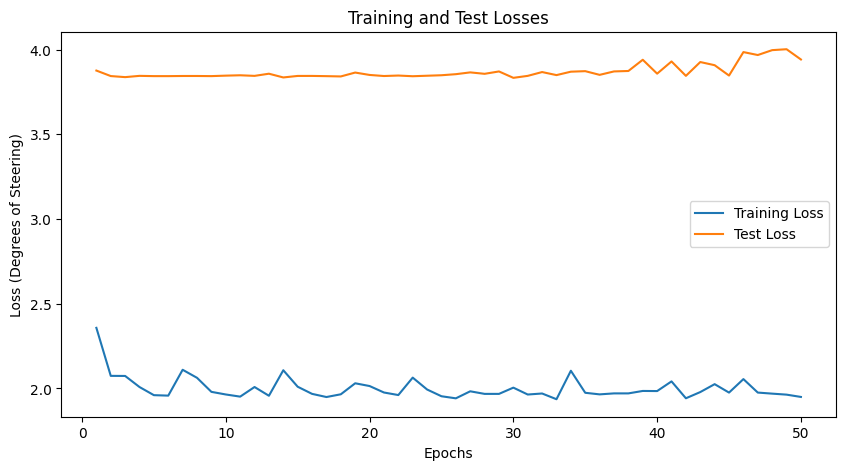

In [17]:
model = setup_model(use_aps, use_stated)

starting_epoch = 0
best_test_loss = np.inf

#Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

if warm_start:
    starting_epoch, best_test_loss = warm_start(model, optimizer)

train_losses = []
test_losses = []

for epoch in range(starting_epoch, num_epochs):
    epoch_train_loss = 0
    for combined_images, steering_angle in train_loader:
      #Move tensors to the configured device
      combined_images = combined_images.to(device)
      steering_angle = steering_angle.to(device)
      #Forward pass
      outputs = model(combined_images)
      loss = criterion(outputs, steering_angle)
      #Backward and optimize
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      epoch_train_loss += loss.item()
      del combined_images, steering_angle, outputs
      torch.cuda.empty_cache()
      gc.collect()

    # Average training loss for the epoch
    epoch_train_loss /= len(train_loader)
    train_losses.append(epoch_train_loss)

    #Validation
    epoch_test_loss = 0
    with torch.no_grad():
          for combined_images, steering_angle in test_loader:
              combined_images = combined_images.to(device)
              steering_angle = steering_angle.to(device)
              outputs = model(combined_images)
              loss = criterion(outputs, steering_angle)
              epoch_test_loss += loss.item()
              del combined_images, steering_angle, outputs
          epoch_test_loss /= len(test_loader)
          # Save every 20 epochs
          if not ((epoch + 1) % 20):
              state = {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                'best_test_loss': best_test_loss
            }
              torch.save(state, f"{save_path}e{epoch + 1}_L{epoch_test_loss:.2f}.pth")
          # Save the best
          if (epoch_test_loss < best_test_loss):
              best_test_loss = epoch_test_loss
              state = {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                'best_test_loss': best_test_loss
            }
              # Delete all files in the "best" folder before saving the new best model
              for files in glob.glob(f"{save_path}/best/*"):
                os.remove(files)
              
              torch.save(state, f"{save_path}/best/e{epoch + 1}_L{epoch_test_loss:.2f}.pth")
          # Save the last model
          state = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': loss,
            'best_test_loss': best_test_loss
          }
        # Delete all files in the "last" folder before saving the new best model
          for files in glob.glob(f"{save_path}/last/*"):
              os.remove(files)
              
          torch.save(state, f"{save_path}/last/e{epoch + 1}_L{epoch_test_loss:.2f}.pth")

          test_losses.append(epoch_test_loss)
          if not ((epoch + 1) % 5):
            print(f"Epoch [{epoch + 1}/{num_epochs}], Train Loss: {epoch_train_loss: .4f} Test Loss: {epoch_test_loss: .4f}")
            
# Plotting the training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label='Training Loss')
plt.plot(range(1, num_epochs + 1), test_losses, label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (Degrees of Steering)')
plt.title('Training and Test Losses')
plt.legend()
plt.show()


In [27]:
# initialize stateful model from the one that doesn't forward states for inference
if use_stated:
    if use_aps:
        alternative_model = ResNet(ResidualBlock, [3, 4, 6, 3], num_channels=2).to(device)
    else:
        alternative_model = ResNet(ResidualBlock, [3, 4, 6, 3], num_channels=1).to(device)
else:
    if use_aps:
        alternative_model = ResNetStated(ResidualBlock, [3, 4, 6, 3], num_channels=2).to(device)
    else:
        alternative_model = ResNetStated(ResidualBlock, [3, 4, 6, 3], num_channels=1).to(device)

alternative_model.load_state_dict(model.state_dict())
model.reset_hidden()

In [22]:
# Function to generate predictions in batches
def generate_predictions(model, data_X, data_y, batch_size, device, transform):
    model.eval()
    predictions = []
    with torch.no_grad():
        for i in range(0, len(data_X) - len(data_X) % batch_size, batch_size):
            batch_X = data_X[i:i+batch_size]
            batch_y = data_y[i:i+batch_size]
            transformed_batch_X = torch.stack([transform(img) for img in batch_X])
            batch_X_tensor = transformed_batch_X.to(device)
            batch_y_tensor = Tensor(batch_y).to(device)
            outputs = model(batch_X_tensor)
            predictions.extend(outputs.detach().cpu().numpy())
            del batch_X_tensor, batch_y_tensor, outputs
            torch.cuda.empty_cache()
            gc.collect()
    return predictions


In [24]:
# Plotting
plt.figure(figsize=(15,15))

# Generate predictions for training set with stateless
train_outputs_np = generate_predictions(model, train_X, train_y, batch_size, device, transform)
train_outputs_np_stateful = generate_predictions(alternative_model, train_X, train_y, batch_size, device, transform)
# Plot training set predictions
plt.subplot(2, 1, 1)
plt.plot(train_y, label="Ground Truth - Training")
plt.plot(train_outputs_np, label="Model Prediction - Training, Stateless")
plt.plot(train_outputs_np_stateful, label="Model Prediction - Training, Stated")
plt.title("Training Angles vs Model Prediction")
plt.xlabel("Data Point")
plt.ylabel("Steering Angle")
plt.legend()

# Generate predictions for testing set with stateless
test_outputs_np = generate_predictions(model, test_X, test_y, batch_size, device, transform)
test_outputs_np_stateful = generate_predictions(alternative_model, test_X, test_y, batch_size, device, transform)
# Plot testing set predictions
plt.subplot(2, 1, 2)
plt.plot(test_y, label="Ground Truth - Testing")
plt.plot(test_outputs_np, label="Model Prediction - Testing, Stateless")
plt.plot(test_outputs_np_stateful, label="Model Prediction - Testing, Stated")
plt.title("Testing Angles vs Model Prediction")
plt.xlabel("Data Point")
plt.ylabel("Steering Angle")
plt.legend()

plt.tight_layout()
plt.show()

RuntimeError: Expected hidden[0] size (1, 32, 128), got [1, 60, 128]

<Figure size 1500x1500 with 0 Axes>